# PyTorch: от логистической регрессии до LeNet

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ignat2008/conv_cnn/blob/main/pytorch_fc_cnn_mnist.ipynb)

В ноутбуке я строю нейронные сети на PyTorch на двух наборах данных и каждый раз прохожу один и тот же путь: подготовка данных → модель → функции обучения и предсказания → обучение и оценка.

1. **Moons** (синтетические данные): логистическая регрессия, написанная вручную на `nn.Parameter`.
2. **MNIST, полносвязные сети**: сравнение функций активации, включая собственные реализации Leaky ReLU и Tanh.
3. **MNIST, свёрточные сети**: эксперименты с ядрами свёртки и обучение LeNet.

**Результаты (accuracy на валидации):** moons — 0.8852, полносвязная сеть на MNIST — 0.9725, LeNet на MNIST — 0.9896.

Во всех экспериментах фиксирую seed (42) для воспроизводимости.

### Импорты

In [ ]:
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.nn import functional as F

from torch.utils.data import TensorDataset, DataLoader
import random
from tqdm.notebook import tqdm

import copy

sns.set(style="darkgrid", font_scale=1.4)

In [ ]:
# Reduce stochasticity

SEED = 42

# PyTorch
torch.manual_seed(SEED)

# CUDA (GPU)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)  # For multi-GPU setups

# NumPy
np.random.seed(SEED)

# Python's built-in random
random.seed(SEED)

In [ ]:
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)

## 1. Moons: логистическая регрессия на PyTorch

### Данные

Генерирую датасет `make_moons` (10 000 точек, шум 0.1) и смотрю на него:

In [ ]:
X, y = make_moons(n_samples=10000, random_state=42, noise=0.1)

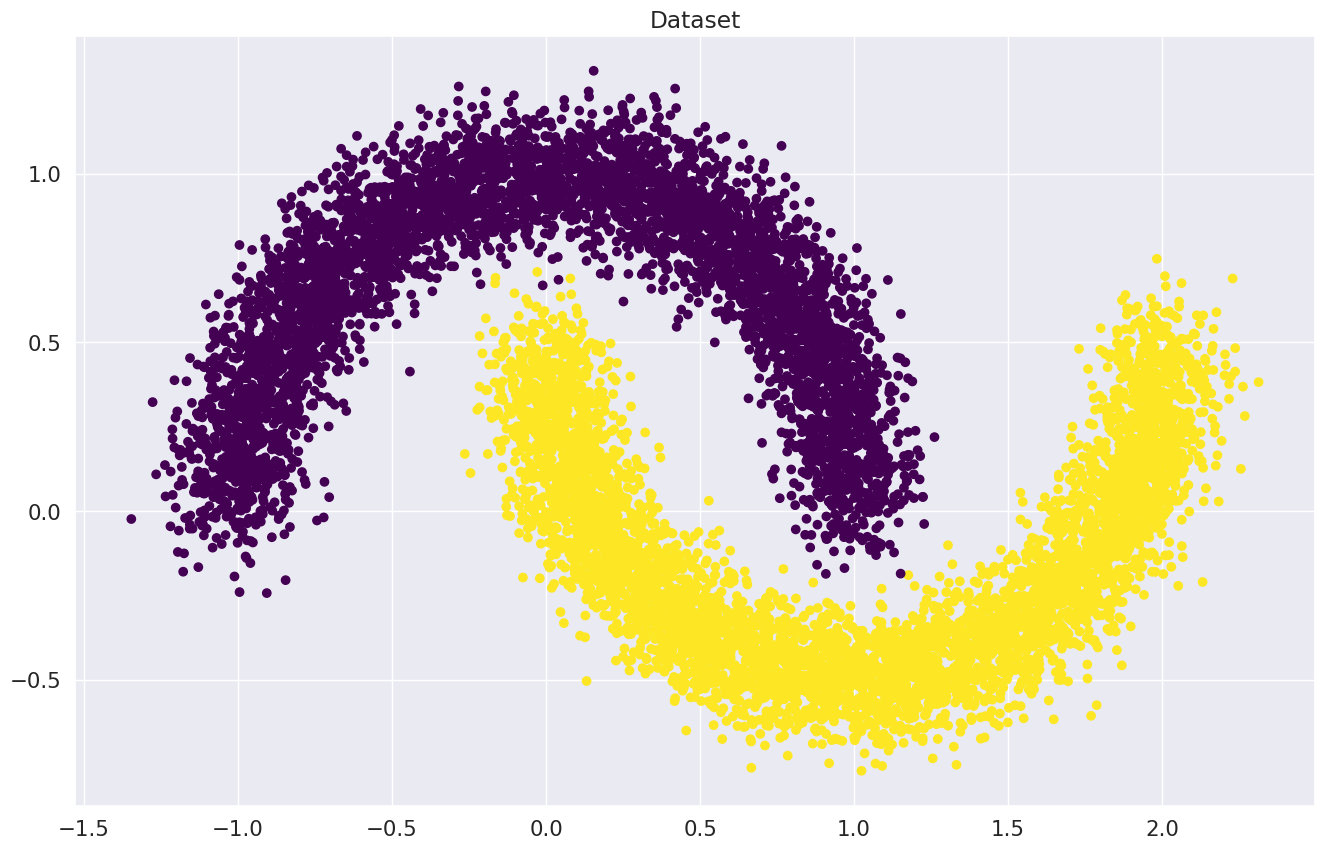

In [ ]:
# Визуализация данных

plt.figure(figsize=(16, 10))
plt.title("Dataset")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="viridis")
plt.show()

Делю данные на train и validation (по умолчанию 75/25).

In [ ]:
X_train, X_val, y_train, y_val = train_test_split(X, y, random_state=42)

### Загрузчики данных

В PyTorch данные загружаются на лету с помощью двух сущностей: `Dataset` отдаёт объекты по одному, а `DataLoader` собирает их в батчи. Датасет небольшой, поэтому использую `TensorDataset`: перевожу массивы numpy в тензоры `torch.float32`.

In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32)

Создаю `Dataset` и `DataLoader`.

**Нужен ли `shuffle`?** Для обучающей выборки да, для валидационной нет. Порядок объектов в датасете может быть упорядочен по какому-то признаку (например, по времени), и сеть начнёт предсказывать классы по этому порядку, а не по закономерностям в данных. Валидационная выборка используется только для проверки качества, поэтому перемешивать её необязательно.

In [ ]:
train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset = TensorDataset(X_val_t, y_val_t)
train_dataloader = DataLoader(train_dataset, batch_size=128, shuffle = True)
val_dataloader = DataLoader(val_dataset, batch_size=128)

### Модель: логистическая регрессия как нейросеть

Логистическая регрессия — это нейронная сеть с одним линейным слоем и сигмоидой. Линейный слой $XW + b$ выдаёт логиты (числа из $(-\infty; \infty)$), а сигмоида

$$\sigma(x) = \frac{1}{1 + e^{-x}}$$

переводит их в вероятность принадлежности к классу 1.

Линейный слой пишу вручную: $logits = XW + b$, где $W$ и $b$ — параметры модели (`nn.Parameter`), без использования `nn.Linear`. Веса инициализирую нормальным распределением (`torch.randn`).

In [ ]:
class LinearRegression(nn.Module):
    def __init__(self, in_features: int, out_features: int, bias: bool = True):
        super().__init__()
        self.weights = nn.Parameter(torch.randn(in_features, out_features))
        self.bias = bias
        if bias:
            self.bias_term = nn.Parameter(torch.randn(out_features))

    def forward(self, x):
        x =  torch.matmul(x, self.weights)
        if self.bias:
            x += self.bias_term
        return x

Функция потерь — [BCEWithLogitsLoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html): она работает непосредственно с логитами, в отличие от [BCELoss](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCELoss.html), которой нужны вероятности (после `sigmoid`).

In [ ]:
linear_regression = LinearRegression(in_features = 2, out_features = 1)
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(linear_regression.parameters(), lr=0.05)

Число обучаемых параметров модели (суммарное количество отдельных чисел, а не тензоров):

In [ ]:
total_params = sum(p.numel() for p in linear_regression.parameters() if p.requires_grad)
print(f"Общее количество обучаемых параметров: {total_params:,}")

Общее количество обучаемых параметров: 3


У модели 3 обучаемых параметра: два веса (по числу признаков) и смещение.

### Функции обучения и предсказания

**Цикл обучения.** Несколько раз (эпох) прохожу по датасету батчами. На каждом батче: обнуляю градиенты, получаю логиты, считаю лосс, делаю `backward()` и шаг оптимизатора. Раз в 100 итераций вывожу accuracy на батче.

Функция `train_model` принимает модель, `DataLoader`, оптимизатор, функцию потерь, максимальное число эпох и порог `tol`. Она возвращает лоссы по всем батчам и параметры модели после каждой эпохи.

Обучение останавливается, когда достигнуто максимальное число эпох или когда средний лосс между соседними эпохами изменился меньше, чем на `tol`.

In [ ]:
# выход по лоссу
def train_model(model, train_dataloader, optimizer, loss_func, max_epochs, tol = 1e-3):
  '''
  args:
    model - модель для обучения
    train_dataloader - loader с обучающей выборкой
    optimizer - оптимизатор, взятый из модуля `torch.optim`
    loss_func - функция потерь, взятая из модуля `torch.nn`
    max_epochs - максимальное количество эпох обучения
    tol - порог, с которым будет сравниваться изменение loss, усредненного по эпохе
  '''

  # создадим переменные (на данный момент - пустые списки), куда будем сохранять
  # лоссы по батчам, усредненные по эпохе лоссы и параметры модели
  batch_losses = []
  epoch_mean_losses = []
  model_param_dict = []

  for epoch in range(max_epochs):
    losses = []    # переменная losses - список, куда будем добавлять значения loss по каждому батчу текущей эпохи
    for it, (X_batch, y_batch) in enumerate(train_dataloader):
        # Далее далее по коду идут стандартные операции цикла обучения:
        optimizer.zero_grad()

        outp = model(X_batch)
        loss = loss_func(outp, y_batch.view(-1, 1))
        loss.backward()

        losses.append(loss.item())
        optimizer.step()

        # Для расчета accuracy вычисляем вероятности и предсказание класса нашей моделью,
        # затем вычисляем среднее значение accuracy для текущего батча
        probabilities = torch.sigmoid(outp)
        preds = (probabilities > 0.5).type(torch.float32)
        batch_acc = (preds == y_batch.view(-1, 1)).sum() / y_batch.size(0)

        # через каждые 100 батчей выводим среднее значение accuracy по батчу
        if (epoch * len(train_dataloader) + it + 1) % 100 == 0:
            print(f"Iteration: {epoch * len(train_dataloader) + it + 1}\nBatch accuracy: {batch_acc}")

    batch_losses = batch_losses + losses    # добавляем список лоссов текущей эпохи к списку лоссов по батчам всех предыдущих эпох
    epoch_mean_losses.append(sum(losses)/len(losses))    # вычисляем средний по текущей эпохе лосс и добавляем к списку по предыдущим эпохам
    model_param_dict.append(copy.deepcopy(model.state_dict()))    # добавляем в список текущие значения параметров модели

    # Ниже реализован ранний выход из цикла обучения. Если разница между средним по эпохе значением loss в текущей
    # и предыдущей эпохах меньше порога tol, то оператор return завершит выполнение функции и обучение прекратится
    if epoch > 0 and abs(epoch_mean_losses[-1] - epoch_mean_losses[-2]) < tol:
          print(f"\nIteration: {epoch * len(train_dataloader) + it +1}. Convergence. Stopping iterations after {epoch + 1} epochs.")
          return batch_losses, model_param_dict

  return batch_losses, model_param_dict

Запускаю обучение с лимитом 100 эпох. Перед повторным запуском нужно заново создать модель и оптимизатор, иначе модель продолжит обучаться с прежних весов.

In [ ]:
# при повторном запуске заново создаём модель и оптимизатор (раскомментировать)

#linear_regression = LinearRegression(2, 1)
#optimizer = torch.optim.SGD(linear_regression.parameters(), lr=0.05)
#linear_regression = LinearRegression(2, 1)
#optimizer = torch.optim.SGD(linear_regression.parameters(), lr=0.05)
losses, model_param_dict = train_model(model = linear_regression,
                                                      train_dataloader = train_dataloader, optimizer = optimizer,
                                                      loss_func = loss_function, max_epochs=100, tol = 1e-3)

Iteration: 100
Batch accuracy: 0.796875
Iteration: 200
Batch accuracy: 0.796875
Iteration: 300
Batch accuracy: 0.7890625
Iteration: 400
Batch accuracy: 0.84375
Iteration: 500
Batch accuracy: 0.875
Iteration: 600
Batch accuracy: 0.90625
Iteration: 700
Batch accuracy: 0.8671875
Iteration: 800
Batch accuracy: 0.8203125
Iteration: 900
Batch accuracy: 0.8203125
Iteration: 1000
Batch accuracy: 0.8671875
Iteration: 1100
Batch accuracy: 0.8828125
Iteration: 1200
Batch accuracy: 0.828125
Iteration: 1300
Batch accuracy: 0.875
Iteration: 1400
Batch accuracy: 0.875
Iteration: 1500
Batch accuracy: 0.8984375

Iteration: 1593. Convergence. Stopping iterations after 27 epochs.


In [ ]:
# веса обученной модели

# вариант 1: через атрибуты класса
print(linear_regression.weights)
print(linear_regression.bias_term)

# вариант 2: через parameters()
#list(linear_regression.parameters())

# вариант 3: через state_dict()
#linear_regression.state_dict()

Parameter containing:
tensor([[ 1.2288],
        [-3.7314]], requires_grad=True)
Parameter containing:
tensor([0.2708], requires_grad=True)


Параметры модели после каждой эпохи сохраняю через `copy.deepcopy(model.state_dict())`. Без копии все элементы списка ссылались бы на один и тот же словарь и менялись бы вместе с обучением.

Обучение сошлось за **1593 итерации** (27 эпох); при другом запуске число итераций будет отличаться.

### Кривая лосса и граница решения

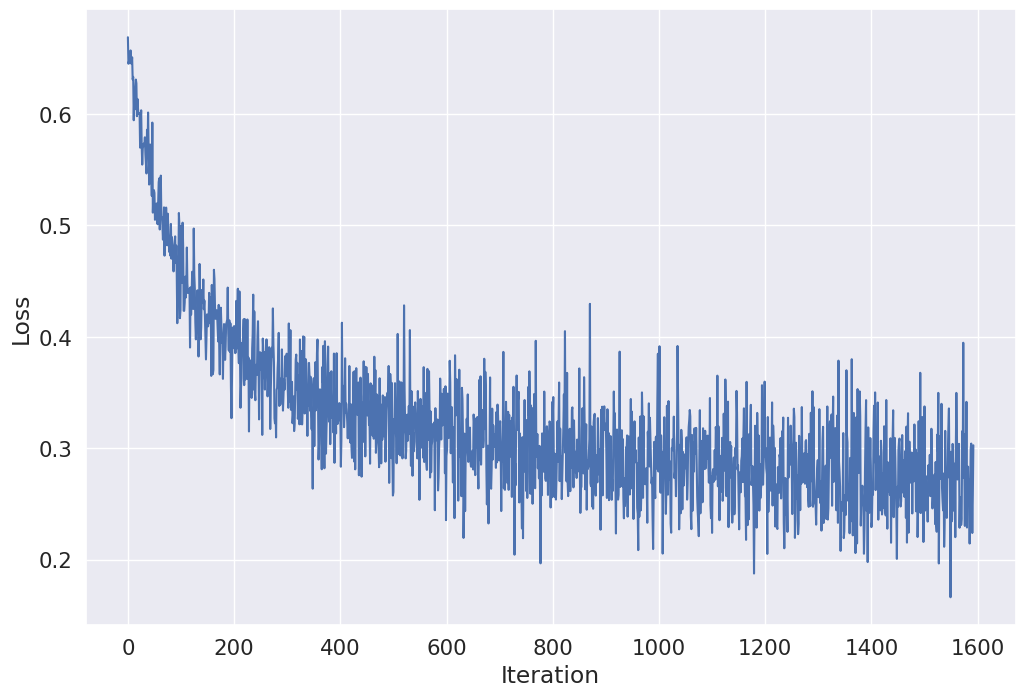

In [ ]:
plt.figure(figsize=(12, 8))
plt.plot(range(len(losses)), losses)
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()

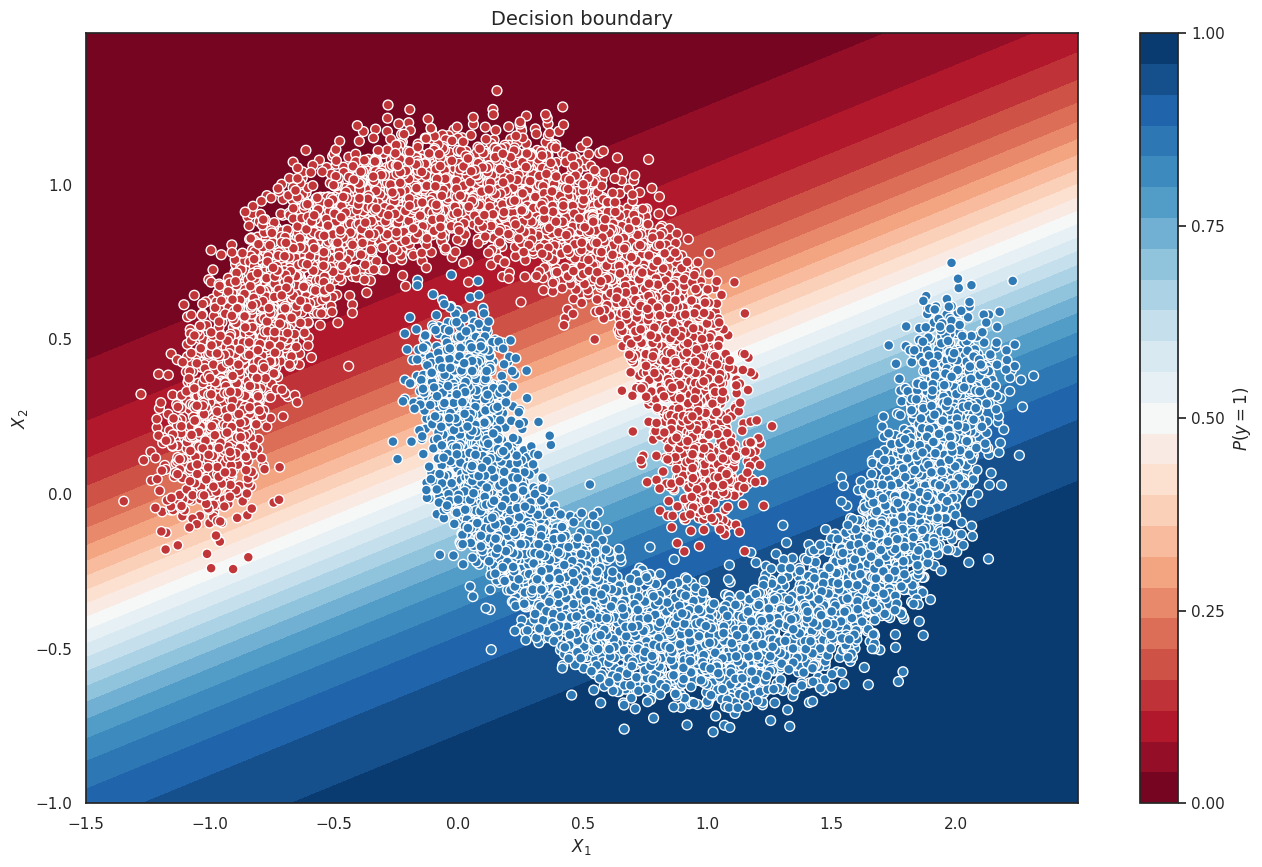

In [ ]:
import numpy as np

sns.set(style="white")

xx, yy = np.mgrid[-1.5:2.5:.01, -1.:1.5:.01]
grid = np.c_[xx.ravel(), yy.ravel()]
batch = torch.from_numpy(grid).type(torch.float32)
with torch.no_grad():
    probs = torch.sigmoid(linear_regression(batch).reshape(xx.shape))
    probs = probs.numpy().reshape(xx.shape)

f, ax = plt.subplots(figsize=(16, 10))
ax.set_title("Decision boundary", fontsize=14)
contour = ax.contourf(xx, yy, probs, 25, cmap="RdBu",
                      vmin=0, vmax=1)
ax_c = f.colorbar(contour)
ax_c.set_label("$P(y = 1)$")
ax_c.set_ticks([0, .25, .5, .75, 1])

ax.scatter(X[100:,0], X[100:, 1], c=y[100:], s=50,
           cmap="RdBu", vmin=-.2, vmax=1.2,
           edgecolor="white", linewidth=1)

ax.set(xlabel="$X_1$", ylabel="$X_2$")
plt.show()

### Предсказание на валидации

Функция `predict` возвращает наиболее вероятный класс для каждого объекта из `DataLoader`.

In [ ]:
@torch.no_grad()
def predict(dataloader, model):
    predictions = np.array([])
    for x_batch, _ in dataloader:
        preds = (torch.sigmoid(model(x_batch)) > 0.5).int()
        preds_numpy = preds.cpu().numpy().flatten()
        predictions = np.append(predictions, preds_numpy)

    return predictions

Сравниваю предсказания с истинными классами валидационной выборки и считаю accuracy:

In [ ]:
from sklearn.metrics import accuracy_score
accuracy_score(y_val, predict(dataloader = val_dataloader, model = linear_regression))

0.8852

**Результат:** accuracy на валидации — **0.8852** (от запуска к запуску значение немного меняется).

## 2. MNIST: полносвязные сети

### Данные

MNIST — рукописные цифры (чёрно-белые изображения 28×28). Загружаю через `torchvision`, нормализую (среднее 0.5, std 0.5) и создаю `DataLoader`-ы с батчем 128: перемешивание только для обучающей выборки.

In [ ]:
import os
from torchvision.datasets import MNIST
from torchvision import transforms as tfs


data_tfs = tfs.Compose([
    tfs.ToTensor(),
    tfs.Normalize((0.5), (0.5))
])

# install for train and test
root = './'
train_dataset_MNIST = MNIST(root, train=True,  transform=data_tfs, download=True)
val_dataset_MNIST  = MNIST(root, train=False, transform=data_tfs, download=True)

train_dataloader_MNIST = DataLoader(train_dataset_MNIST, batch_size=128, shuffle= True)
valid_dataloader_MNIST = DataLoader(val_dataset_MNIST, batch_size=128)

# Далее будем использовать словарь из загрузчиков
loaders_MNIST = {"train": train_dataloader_MNIST, "valid": valid_dataloader_MNIST}

### Полносвязная сеть

Сеть на `nn.Sequential`: `Flatten` → `Linear(784, 128)` → ELU → `Linear(128, 128)` → ELU → `Linear(128, 10)`.

In [ ]:
activation = nn.ELU()

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    activation,
    nn.Linear(128,128),
    activation,
    nn.Linear(128,10),

)

Функция потерь — кросс-энтропия:

$$
L = -\frac{1}{N} \sum_{n=1}^{N} \sum_{i=1}^{C} y_{ni} \log(\hat{y}_{ni}),
$$

где $N$ — число объектов, $C$ — число классов, $y_{ni}$ — истинная метка (one-hot), $\hat{y}_{ni}$ — предсказанная вероятность класса $i$ для объекта $n$. Оптимизатор — Adam.

In [ ]:
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters())

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

### Функции обучения и валидации

Три функции: `fit_one_epoch` (одна эпоха обучения), `eval_one_epoch` (одна эпоха валидации) и `train_func` (цикл по эпохам). В обучении модель переводится в режим `train`, а в валидации — в режим `eval` с отключённым расчётом градиентов (`torch.no_grad()`).

In [ ]:
def fit_one_epoch(model, train_dataloader, optimizer, loss_func):
  '''
  args:
    model - модель для обучения
    train_dataloader - loader с выборкой для обучения модели
    optimizer - оптимизатор, взятый из модуля `torch.optim`
    loss_func - функция потерь, взятая из модуля `torch.nn`

  функция возвращает метрику accuracy по эпохе на данных из train_dataloader
  '''

  epoch_correct_predictions = 0.0
  epoch_all_predictions = 0.0
  model.train()  # переводим модель в режим train

  for X_batch, y_batch in tqdm(train_dataloader):
    # Далее далее по коду идут стандартные операции цикла обучения:
    optimizer.zero_grad()  # обнуляем градиенты модели

    outp = model(X_batch)
    loss = loss_func(outp, y_batch)

    loss.backward()  # считаем градиенты
    optimizer.step()  # делаем шаг градиентного спуска

    # Рассчитаем accuracy. Для этого определим количество верных предсказаний
    # и общее количество предсказаний в каждом батче, а затем накопительным итогом посчитаем
    #  количество верных предсказаний и общее количество предсказаний в рамках эпохи
    preds = outp.argmax(-1)
    batch_correct_predictions = (preds == y_batch).sum().item()
    batch_all_predictions = len(preds)

    epoch_correct_predictions += batch_correct_predictions
    epoch_all_predictions += batch_all_predictions

  epoch_accuracy = epoch_correct_predictions/epoch_all_predictions
  return epoch_accuracy

In [ ]:
# проверим работу функции
fit_one_epoch(model = model, train_dataloader = train_dataloader_MNIST, optimizer = optimizer, loss_func = criterion)

0.8885166666666666

In [ ]:
def eval_one_epoch(model, val_dataloader):
  '''
  args:
    model - модель для обучения
    val_dataloader - loader с валидационной/тестовой выборкой
  '''

  epoch_correct_predictions = 0.0
  epoch_all_predictions = 0.0
  model.eval()  # Переводим модель в режим eval

  for X_batch, y_batch in tqdm(val_dataloader):
    # Далее далее по коду идут стандартные операции цикла валидации:
      with torch.no_grad():  # Не забываем отключить расчет градиентов
          outp = model(X_batch)  # Получаем "логиты" из модели
          preds = outp.argmax(-1)  # Определяем наиболее вероятный класс для каждого объекта в батче

    # Рассчитаем accuracy
          batch_correct_predictions = (preds == y_batch).sum().item()
          batch_all_predictions = len(preds)

          epoch_correct_predictions += batch_correct_predictions
          epoch_all_predictions += batch_all_predictions

  epoch_accuracy = epoch_correct_predictions / epoch_all_predictions
  return epoch_accuracy

In [ ]:
# проверим работу функции
eval_one_epoch(model = model, val_dataloader = valid_dataloader_MNIST)

0.9371

`train_func` запускает обучение и валидацию заданное число эпох и возвращает accuracy на обучающей и валидационной выборках по эпохам.

In [ ]:
def train_func(model, num_epochs, dataloaders, optimizer, loss_func):
  '''
  args:
    model - модель для обучения
    num_epochs - количество эпох
    dataloaders - словарь loader'ов с обучающей и валидационной выборками
    optimizer - оптимизатор, взятый из модуля `torch.optim`
    loss_func - функция потерь, взятая из модуля `torch.nn`

  функция возвращает accuracy на обучающей и валидационной выборках на каждой эпохе
  '''

  accuracy = {"train": [], "valid": []}
  for epoch in range(num_epochs):
    print(f"\nEpoch: {epoch+1}")

    accuracy_train_one_epoch = fit_one_epoch(model = model, train_dataloader = dataloaders['train'], optimizer = optimizer, loss_func = loss_func)
    print(f"Accuracy_train: {accuracy_train_one_epoch}\n")

    accuracy_test_one_epoch = eval_one_epoch(model = model, val_dataloader = dataloaders['valid'])
    print(f"Accuracy_test: {accuracy_test_one_epoch}\n")

    accuracy['train'].append(accuracy_train_one_epoch)
    accuracy['valid'].append(accuracy_test_one_epoch)
  return accuracy

In [ ]:
# обучение на 10 эпохах
optimizer = torch.optim.Adam(model.parameters())
max_epochs = 10
accuracy = train_func(model = model, num_epochs = max_epochs, dataloaders = loaders_MNIST, optimizer = optimizer, loss_func = criterion)


Epoch: 1


Accuracy_train: 0.9484166666666667



Accuracy_test: 0.9558


Epoch: 2


Accuracy_train: 0.9634333333333334



Accuracy_test: 0.9684


Epoch: 3


Accuracy_train: 0.9709666666666666



... (11 outputs left out)

Accuracy_train: 0.9878333333333333



Accuracy_test: 0.9792


Epoch: 10


Accuracy_train: 0.9876833333333334



Accuracy_test: 0.9725



**Результат:** после 10 эпох accuracy на train — 0.9877, на validation — 0.9725 (максимум на validation — 0.9792 на 9-й эпохе).

### Сравнение функций активации

Функции активации добавляют сети нелинейность: без них композиция линейных слоёв остаётся линейным преобразованием. Сравниваю следующие:

| Функция | Формула | Диапазон значений |
|---|---|---|
| ReLU | $\max(0, x)$ | $[0, \infty)$ |
| Leaky ReLU | $\max(\alpha x, x)$, обычно $\alpha = 0.01$ | $(-\infty, \infty)$ |
| ELU | $x$ при $x > 0$; $\alpha (e^x - 1)$ при $x \leq 0$ | $(-\alpha, \infty)$ |
| Tanh | $\dfrac{e^x - e^{-x}}{e^x + e^{-x}}$ | $(-1, 1)$ |
| Линейная (тождественная) | $x$ | $(-\infty, \infty)$ |

Линейная функция нелинейности не добавляет, это контрольный вариант.

#### Собственные реализации активаций

Пишу классы Leaky ReLU и Tanh: прямой проход (`forward`) и градиент (`backward`), считаемый аналитически. Затем сверяю их с реализациями PyTorch (значения и градиенты).

Начинаю с ReLU:

In [ ]:
class ReLU(nn.Module):
  def __init__(self, ):
    super().__init__()


  def forward(self, x):
    return torch.maximum(torch.zeros_like(x), x)

  def backward(self, x):
    grads = torch.zeros_like(x)
    grads[x > 0] = 1
    return grads


In [ ]:
# test forward pass

torch_relu = nn.ReLU()
your_relu = ReLU()

x = torch.linspace(-3, 3, 100, requires_grad=True)


x_relu_custom = your_relu(x)
x_relu_torch = torch_relu(x)

assert torch.allclose(x_relu_custom, x_relu_torch)

In [ ]:
grad_relu_custom = your_relu.backward(x)

x_relu_torch.sum().backward()
grad_relu_torch = x.grad.clone()
x.grad.zero_()

assert torch.allclose(grad_relu_custom, grad_relu_torch)

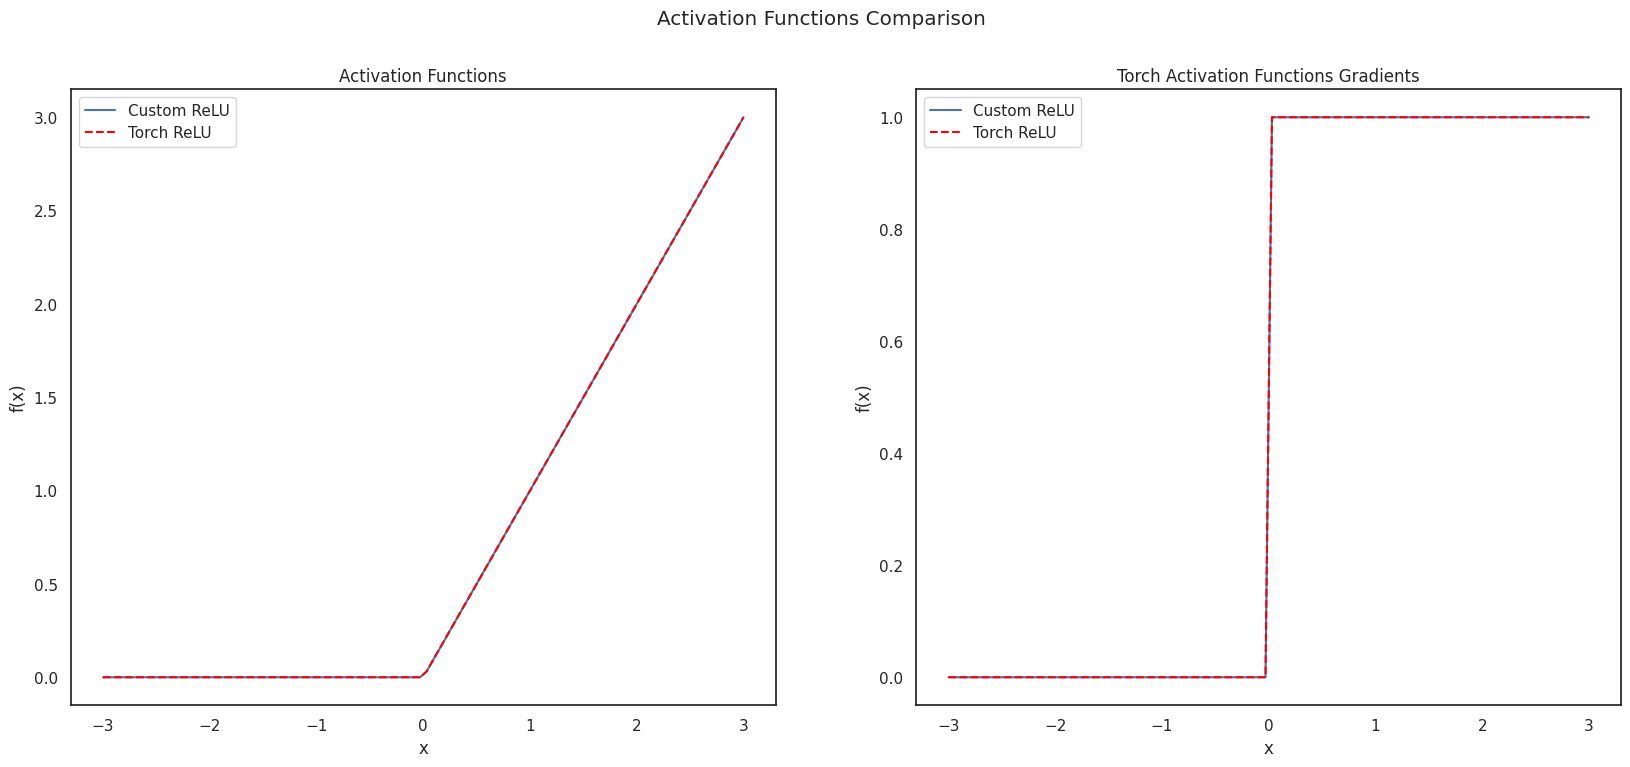

In [ ]:
# Plot custom and torch functions
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Activation Functions Comparison")

# Plot Custom Functions
axes[0].set_title("Activation Functions")
axes[0].plot(x.detach().numpy(), x_relu_custom.detach().numpy(), label="Custom ReLU")
axes[0].plot(x.detach().numpy(), x_relu_torch.detach().numpy(), color='red', label="Torch ReLU", linestyle='--')
axes[0].legend()
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")

# Plot Torch Functions
axes[1].set_title("Torch Activation Functions Gradients")
axes[1].plot(x.detach().numpy(), grad_relu_custom.detach().numpy(), label="Custom ReLU")
axes[1].plot(x.detach().numpy(), grad_relu_torch.detach().numpy(), color='red', label="Torch ReLU", linestyle='--')
axes[1].legend()
axes[1].set_xlabel("x")
axes[1].set_ylabel("f(x)")

plt.show()

Leaky ReLU и Tanh:

In [ ]:
class LeakyReLU(nn.Module):
    def __init__(self, alpha):
        super().__init__()
        self.alpha = alpha


    def forward(self, x):
        return torch.maximum(self.alpha * x, x)

    def backward(self, x):
        with torch.no_grad():
            grads = torch.ones_like(x)
            grads[x < 0] = self.alpha
            return grads

class Tanh(nn.Module):
    def __init__(self, ):
        super().__init__()


    def forward(self, x):
        return torch.tanh(x)

    def backward(self, x):
        with torch.no_grad():
            return 1 - torch.tanh(x) ** 2





In [ ]:
# lets test your functions with torch functions

torch_leaky_relu = nn.LeakyReLU(negative_slope=0.01)
torch_tanh = nn.Tanh()


your_leaky_relu = LeakyReLU(0.01)
your_tanh = Tanh()


In [ ]:
# Test forward pass
x_leaky_custom = your_leaky_relu(x)
x_leaky_torch = torch_leaky_relu(x)

assert torch.allclose(x_leaky_custom, x_leaky_torch)

x_tanh_custom = your_tanh(x)
x_tanh_torch = torch_tanh(x)

assert torch.allclose(x_tanh_custom, x_tanh_torch)


In [ ]:
grad_leaky_custom = your_leaky_relu.backward(x)


x.grad.zero_()
x_leaky_torch.sum().backward()
grad_leaky_torch = x.grad.clone()

assert torch.allclose(grad_leaky_custom, grad_leaky_torch)

grad_tanh_custom = your_tanh.backward(x)

x.grad.zero_()
x_tanh_torch.sum().backward()
grad_tanh_torch = x.grad.clone()

assert torch.allclose(grad_tanh_custom, grad_tanh_torch)



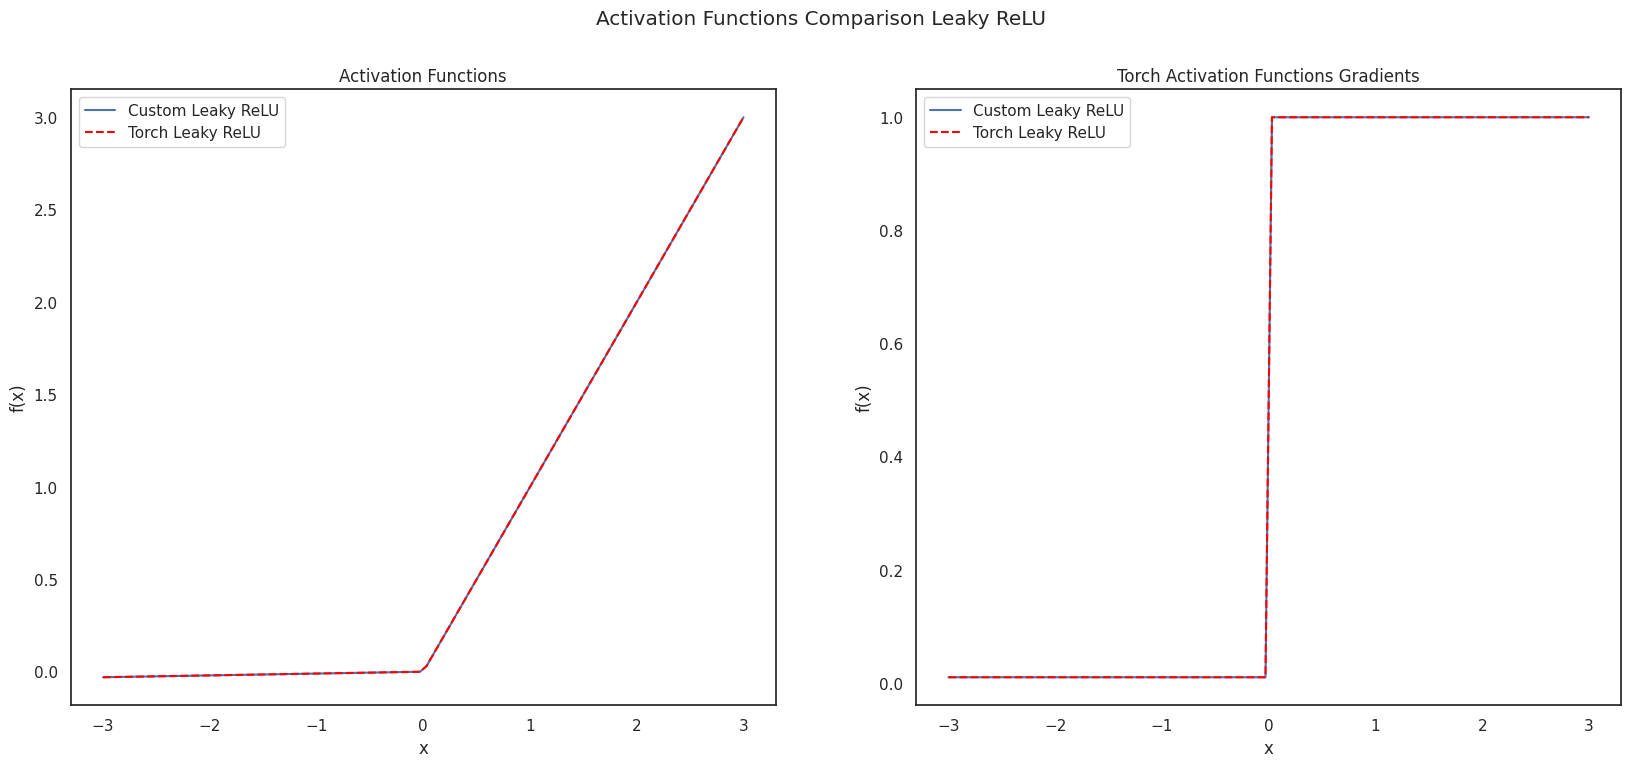

In [ ]:

# Plot custom and torch functions
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Activation Functions Comparison Leaky ReLU")

# Plot Custom Functions
axes[0].set_title("Activation Functions")
axes[0].plot(x.detach().numpy(), x_leaky_custom.detach().numpy(), label="Custom Leaky ReLU")
axes[0].plot(x.detach().numpy(), x_leaky_torch.detach().numpy(), color='red', label="Torch Leaky ReLU", linestyle='--')
axes[0].legend()
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")

# Plot Torch Functions
axes[1].set_title("Torch Activation Functions Gradients")
axes[1].plot(x.detach().numpy(), grad_leaky_custom.detach().numpy(), label="Custom Leaky ReLU")
axes[1].plot(x.detach().numpy(), grad_leaky_torch.detach().numpy(), color='red', label="Torch Leaky ReLU", linestyle='--')
axes[1].legend()
axes[1].set_xlabel("x")
axes[1].set_ylabel("f(x)")

plt.show()

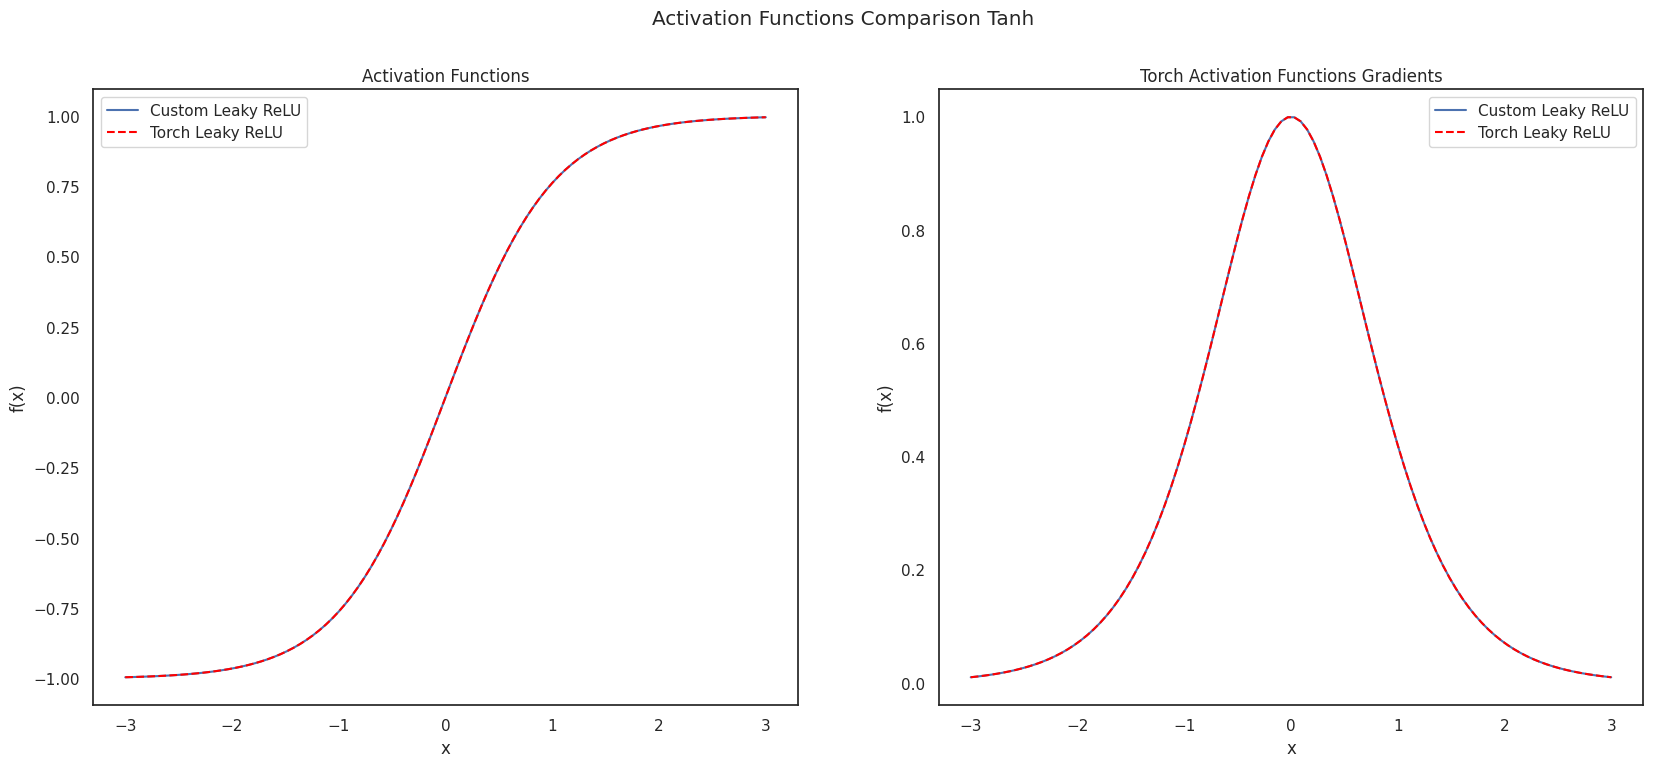

In [ ]:
# Plot custom and torch functions
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
fig.suptitle("Activation Functions Comparison Tanh")

# Plot Custom Functions
axes[0].set_title("Activation Functions")
axes[0].plot(x.detach().numpy(), x_tanh_custom.detach().numpy(), label="Custom Leaky ReLU")
axes[0].plot(x.detach().numpy(), x_tanh_torch.detach().numpy(), color='red', label="Torch Leaky ReLU", linestyle='--')
axes[0].legend()
axes[0].set_xlabel("x")
axes[0].set_ylabel("f(x)")

# Plot Torch Functions
axes[1].set_title("Torch Activation Functions Gradients")
axes[1].plot(x.detach().numpy(), grad_tanh_custom.detach().numpy(), label="Custom Leaky ReLU")
axes[1].plot(x.detach().numpy(), grad_tanh_torch.detach().numpy(), color='red', label="Torch Leaky ReLU", linestyle='--')
axes[1].legend()
axes[1].set_xlabel("x")
axes[1].set_ylabel("f(x)")

plt.show()

#### Сравнение активаций на MNIST

Для каждой функции активации обучаю сеть `784 → 128 → активация → 10` и сравниваю accuracy на валидации по эпохам.

In [ ]:

# для функции активации ELU() воспользуемся полученной ранее оценкой accuracy
elu_accuracy = accuracy["valid"]

Функция `test_activation_function` создаёт и обучает сеть с заданной активацией.

Замечание: кривая ELU взята из предыдущего эксперимента (сеть с двумя скрытыми слоями), поэтому её сравнение с остальными вариантами (один скрытый слой) приблизительное.

In [ ]:
def test_activation_function(activation):
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(784, 128),
        activation,
        nn.Linear(128,10)

        )
    optimizer = torch.optim.Adam(model.parameters())
    accuracy = train_func(model = model, num_epochs = max_epochs, dataloaders =  loaders_MNIST, optimizer = optimizer, loss_func = criterion)

    return accuracy

In [ ]:
plain_accuracy = test_activation_function(activation = nn.Identity())['valid'] #There is no non-linearity
relu_accuracy = test_activation_function(activation = nn.ReLU())['valid']
leaky_relu_accuracy = test_activation_function(activation = nn.LeakyReLU())['valid']
tanh_accuracy =  test_activation_function(activation = nn.Tanh())['valid']


Epoch: 1


Accuracy_train: 0.8737



Accuracy_test: 0.9028


Epoch: 2


Accuracy_train: 0.90705



Accuracy_test: 0.9117


Epoch: 3


Accuracy_train: 0.9109333333333334



... (71 outputs left out)

Accuracy_train: 0.9824166666666667



Accuracy_test: 0.9716


Epoch: 10


Accuracy_train: 0.9842



Accuracy_test: 0.9725



### Accuracy на валидации по эпохам

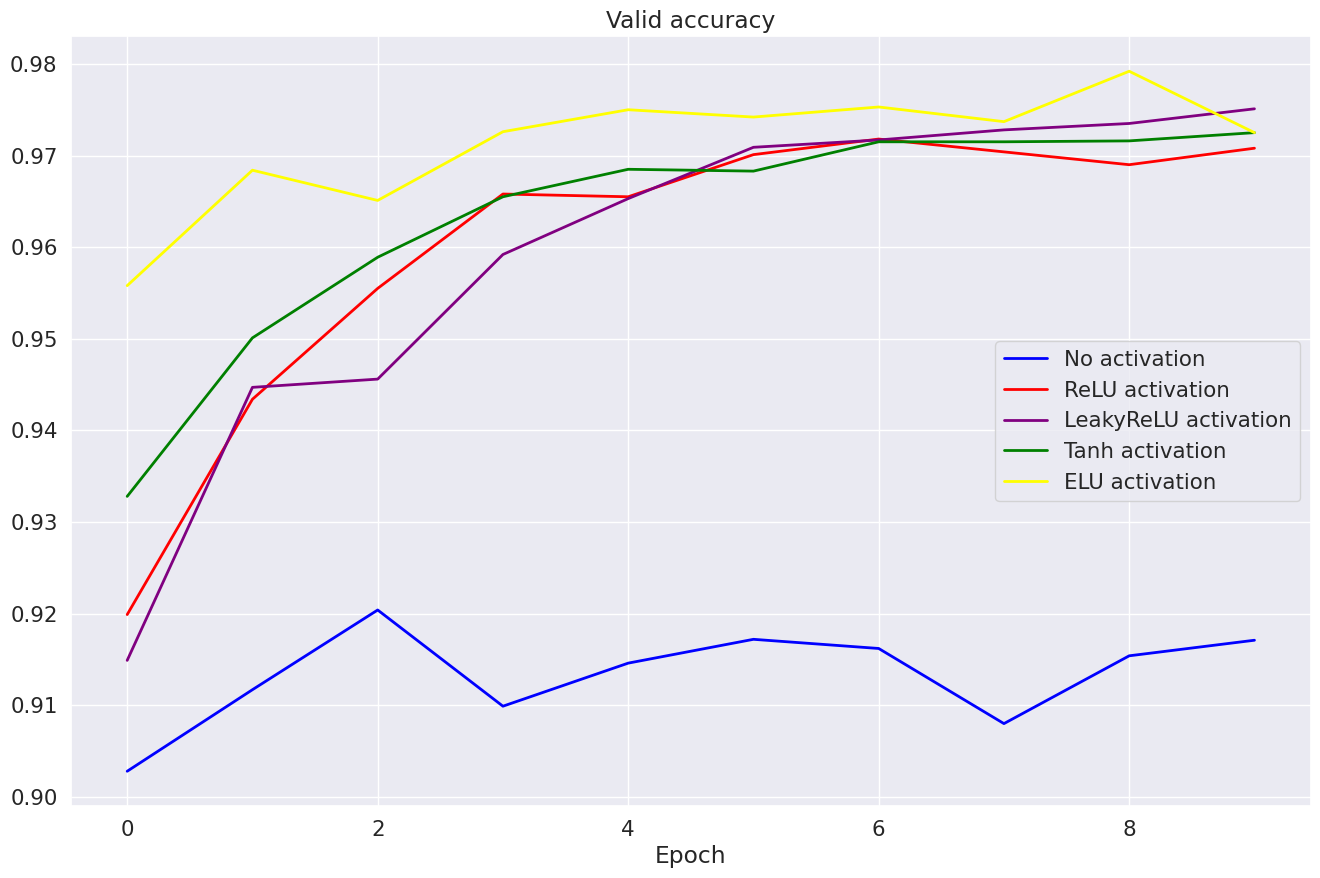

In [ ]:
sns.set(style="darkgrid", font_scale=1.4)

plt.figure(figsize=(16, 10))
plt.title("Valid accuracy")
plt.plot(range(max_epochs), plain_accuracy, label="No activation", linewidth=2, color = 'blue')
plt.plot(range(max_epochs), relu_accuracy, label="ReLU activation", linewidth=2, color = 'red')
plt.plot(range(max_epochs), leaky_relu_accuracy, label="LeakyReLU activation", linewidth=2, color = 'purple')
plt.plot(range(max_epochs), tanh_accuracy, label="Tanh activation", linewidth=2, color = 'green')
plt.plot(range(max_epochs), elu_accuracy, label="ELU activation", linewidth=2, color = 'yellow')
plt.legend()
plt.xlabel("Epoch")
plt.show()

**Вывод:** к концу обучения наивысший accuracy на валидации у **LeakyReLU** (0.9751), далее Tanh (0.9725) и ReLU (0.9708). Без нелинейности (тождественная функция) сеть достигает лишь 0.9171.

## 3. Свёрточные сети

### Ядра свёртки

Сначала смотрю, как разные ядра 3×3 меняют фотографию.

In [ ]:
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt

import torch
from torch import nn
from torch.nn import functional as F



In [ ]:
!wget https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg -O sample_photo.jpg

(512, 512, 3)


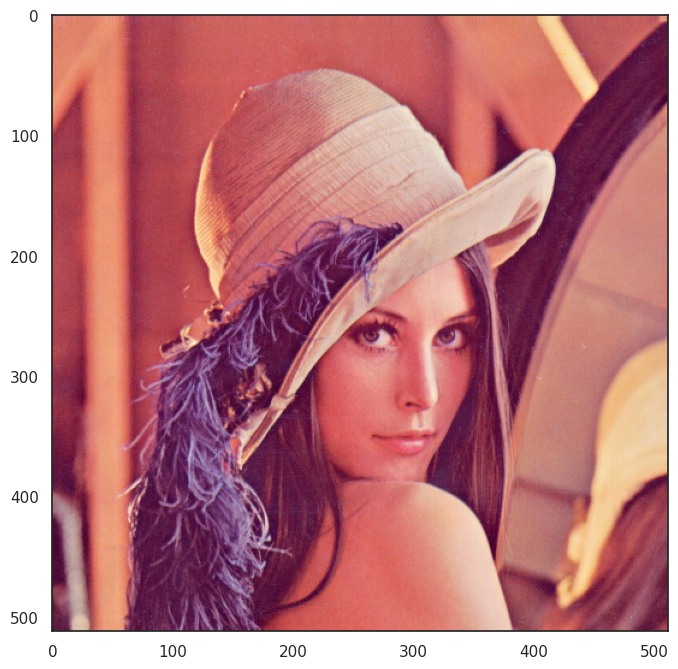

In [ ]:
import cv2
sns.set(style="white")
img = cv2.imread("sample_photo.jpg")
dimensions = img.shape
print(dimensions)
RGB_img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.figure(figsize=(12, 8))
plt.imshow(RGB_img)
plt.show()

Шесть ядер (А–Е):

- А — тождественное;
- Б — вторая производная по вертикали;
- В — вторая производная по горизонтали;
- Г — лапласиан;
- Д — повышение резкости;
- Е — размытие (гауссово ядро 3×3).

In [ ]:
conv_1 = np.array([[0, 0, 0], [0, 1, 0], [0, 0, 0]]) # A
conv_2 = np.array([[0, 1, 0], [0, -2, 0], [0, 1, 0]]) # Б
conv_3 = np.array([[0, 0, 0], [1, -2, 1], [0, 0, 0]]) # В
conv_4 = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]]) # Г
conv_5 = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]) # Д
conv_6 = np.array([[0.0625, 0.125, 0.0625], [0.125, 0.25, 0.125], [0.0625, 0.125, 0.0625]]) # E

In [ ]:
def show_conv_transformation(image, convolution):
  img_t = torch.from_numpy(image).type(torch.float32).unsqueeze(0)
  img_t = img_t.permute(0, 3, 1, 2)  # [BS, H, W, C] -> [BS, C, H, W]
  img_t = nn.ReflectionPad2d(1)(img_t)  # Pad Image for same output size

  kernel = torch.tensor(convolution).reshape(1, 1, 3, 3).type(torch.float32)
  kernel = kernel.repeat(3, 3, 1, 1)

  result = F.conv2d(img_t, kernel)[0]
  result = torch.clip(input = result, min = 0, max = 256*3)

  plt.figure(figsize=(12, 8))
  result_np = result.permute(1, 2, 0).numpy() / 256 / 3
  plt.imshow(result_np)
  plt.show()

  return None

Результат применения каждого ядра (А–Е по порядку):

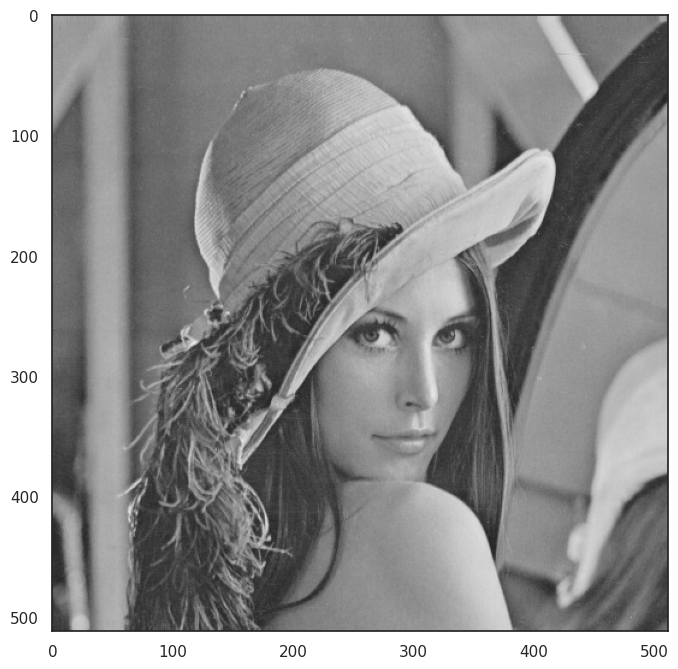

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_1)

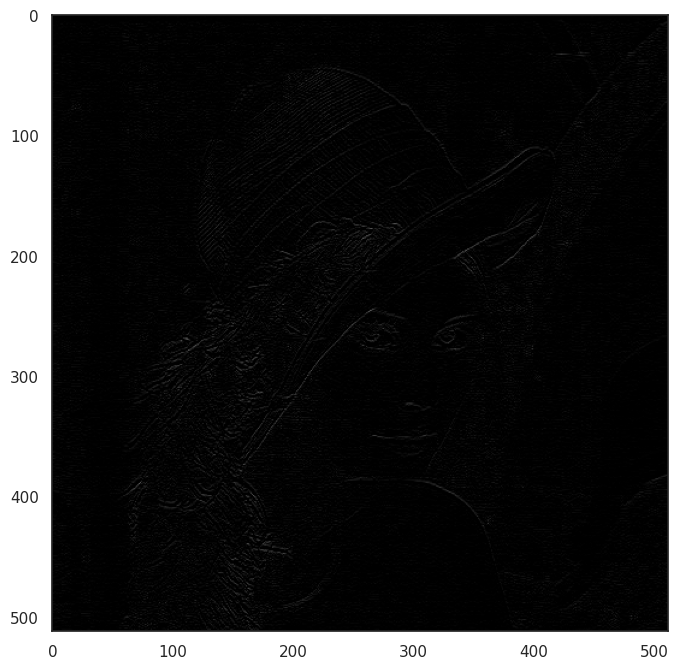

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_2)

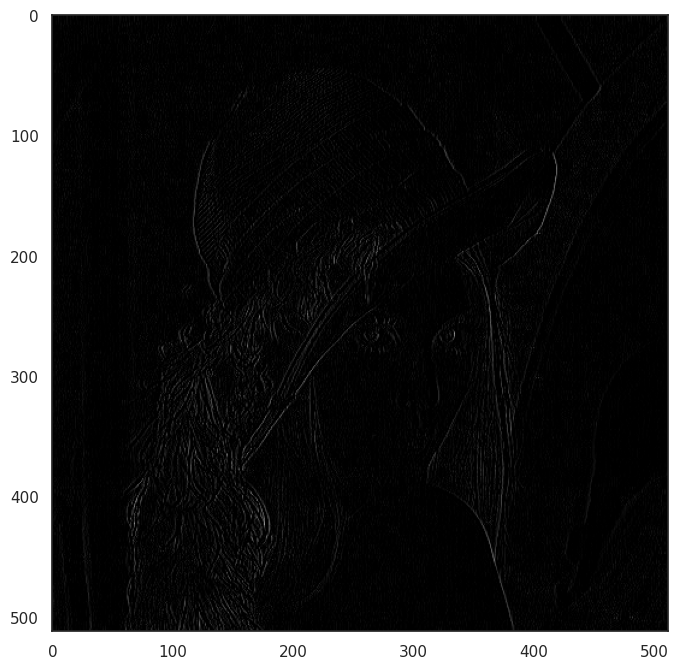

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_3)

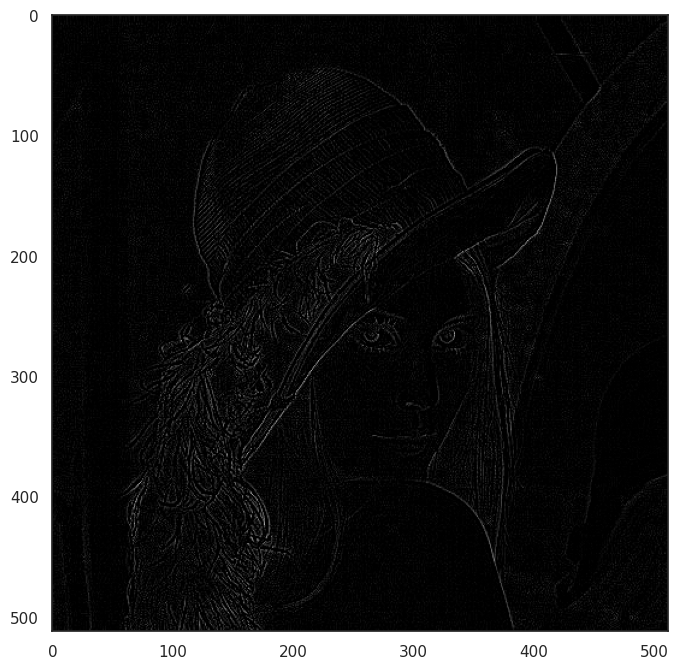

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_4)

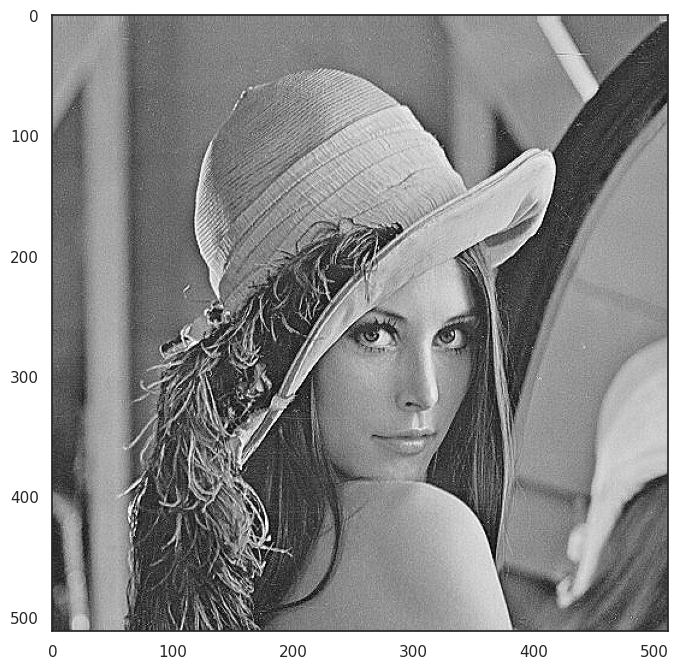

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_5)

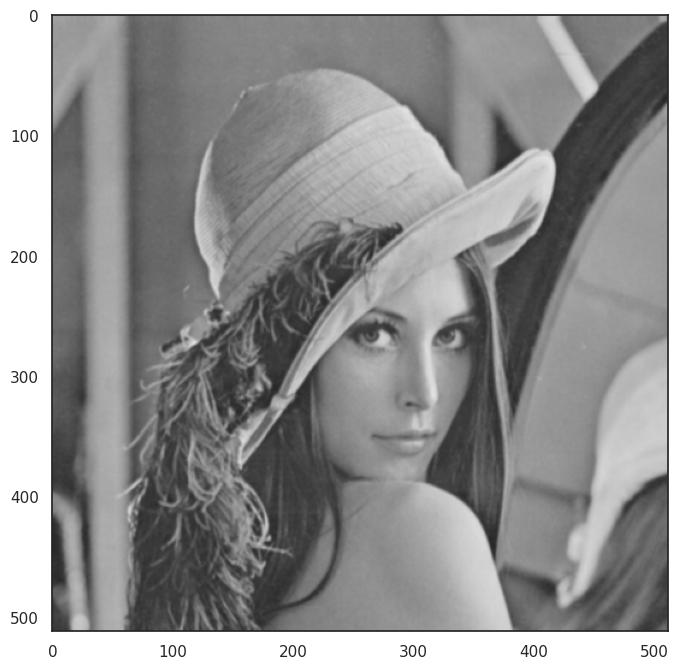

In [ ]:
show_conv_transformation(image = RGB_img, convolution = conv_6)

**Что делает каждое ядро:**

- А — тождественное преобразование;
- Б — выделение горизонтальных границ;
- В — выделение вертикальных границ;
- Г — выделение границ;
- Д — увеличение резкости;
- Е — размытие.

### LeNet

Архитектура LeNet (1998), написанная модульно (без `Sequential`):

1. свёртка 3×3 (1 → 6 карт) + ReLU, MaxPool 2×2;
2. свёртка 3×3 (6 → 16 карт) + ReLU, MaxPool 2×2;
3. `Flatten`;
4. полносвязные слои: 120 нейронов + ReLU, 84 нейрона + ReLU, выход на 10 классов.

In [ ]:
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        # 1 input image channel, 6 output channels, 3x3 square conv kernel
        self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 6, kernel_size = 3)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv2 = nn.Conv2d(in_channels = 6, out_channels = 16, kernel_size = 3)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)

        self.fl = nn.Flatten()
        self.fc1 = nn.Linear(400, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool1(x)
        x = F.relu(self.conv2(x))
        x = self.pool2(x)
        x = self.fl(x)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)

        return x

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
model_LeNet = LeNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_LeNet.parameters())

loaders_MNIST = {"train": train_dataloader_MNIST, "valid": valid_dataloader_MNIST}

### Обучение LeNet

Использую функции обучения из части про полносвязные сети. Дополнительно в цикл добавлены валидация каждые `val_step` эпох и сохранение весов на промежуточных эпохах (`saved_weights`): с какого-то момента модель может переобучаться, и тогда веса с более ранних шагов оказываются лучше.

In [ ]:
def train_func_lenet(model, num_epochs, dataloaders, optimizer, loss_func, val_step):
  '''
  args:
    model - модель для обучения
    num_epochs - количество эпох
    dataloaders - словарь loader'ов с обучающей и валидационной выборками
    optimizer - оптимизатор, взятый из модуля `torch.optim`
    loss_func - функция потерь, взятая из модуля `torch.nn`
    val_step - шаг проведения валидации
  функция возвращает accuracy на обучающей и валидационной выборках на каждой эпохе
  '''
  saved_weights = {}
  accuracy = {"train": [], "valid": []}
  for epoch in range(num_epochs):
    print(f"\nEpoch: {epoch+1}")

    accuracy_train_one_epoch = fit_one_epoch(model = model, train_dataloader = dataloaders['train'], optimizer = optimizer, loss_func = loss_func)
    print(f"Accuracy_train: {accuracy_train_one_epoch}\n")
    if (epoch + 1) % val_step == 0:
            # Запускаем валидацию
            accuracy_test_one_epoch = eval_one_epoch(
                model=model, val_dataloader=dataloaders["valid"]
            )
            print(f"Accuracy_test: {accuracy_test_one_epoch}\n")
            saved_weights[epoch + 1] = copy.deepcopy(model.state_dict())
            accuracy['valid'].append(accuracy_test_one_epoch)
    accuracy['train'].append(accuracy_train_one_epoch)

  return accuracy

In [ ]:
accuracy = train_func_lenet(model = model_LeNet, num_epochs= 10, dataloaders = loaders_MNIST, optimizer = optimizer, loss_func = criterion, val_step = 1)


Epoch: 1


Accuracy_train: 0.9939833333333333



Accuracy_test: 0.9896


Epoch: 2


Accuracy_train: 0.9953



Accuracy_test: 0.99


Epoch: 3


Accuracy_train: 0.9954833333333334



... (11 outputs left out)

Accuracy_train: 0.9973666666666666



Accuracy_test: 0.9884


Epoch: 10


Accuracy_train: 0.9968



Accuracy_test: 0.9896



In [ ]:
lenet_accuracy = accuracy["valid"]

In [ ]:
b=0
for i in lenet_accuracy:
  b+=i
b/10

0.98935

Средний accuracy на валидации по 10 эпохам — 0.98935, после последней эпохи — 0.9896.

### Сравнение с предыдущими моделями

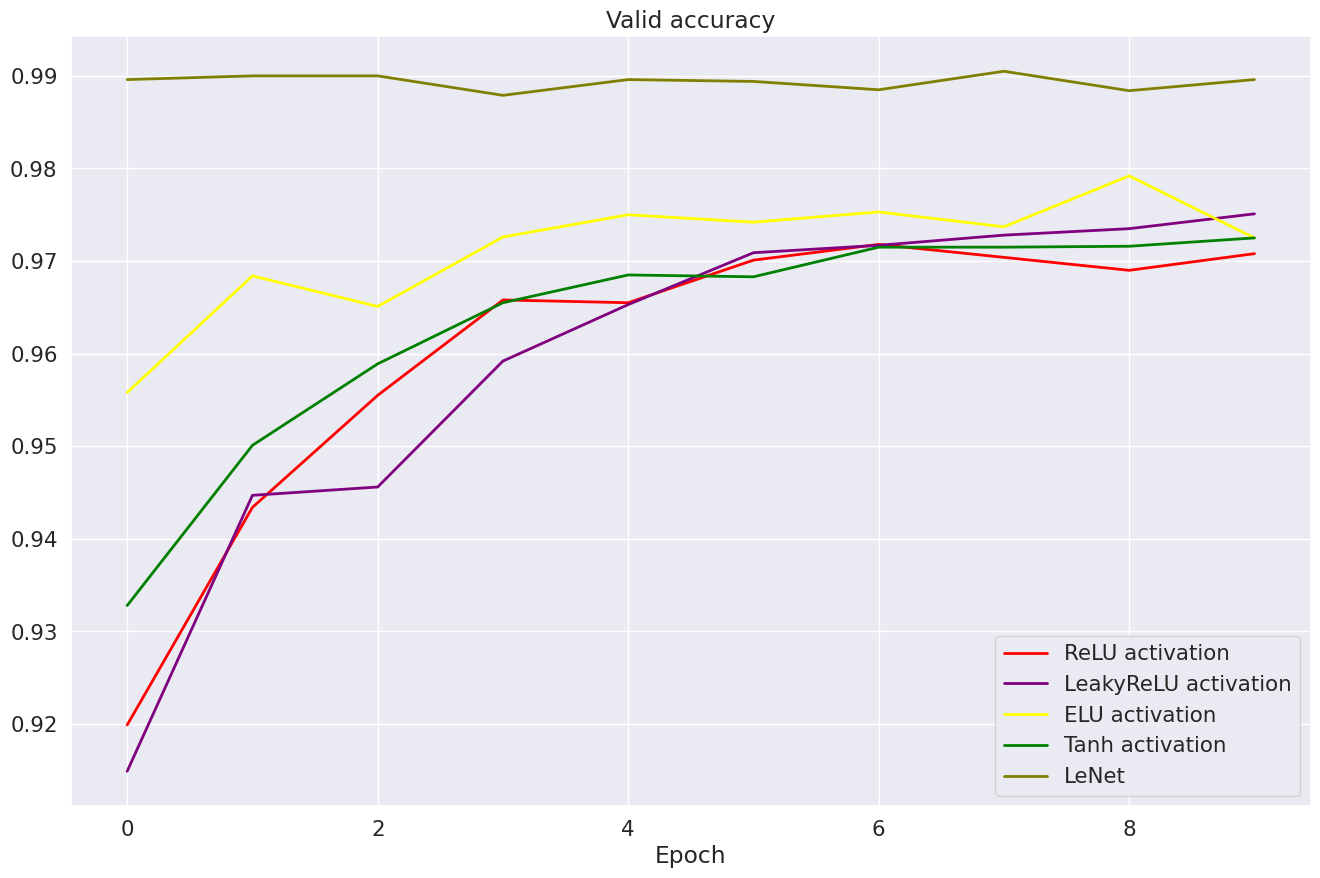

In [ ]:
sns.set(style="darkgrid", font_scale=1.4)

plt.figure(figsize=(16, 10))
plt.title("Valid accuracy")
plt.plot(range(max_epochs), relu_accuracy, label="ReLU activation", linewidth=2, color = 'red')
plt.plot(range(max_epochs), leaky_relu_accuracy, label="LeakyReLU activation", linewidth=2, color = 'purple')
plt.plot(range(max_epochs), elu_accuracy, label="ELU activation", linewidth=2, color = 'yellow')
plt.plot(range(max_epochs), tanh_accuracy, label="Tanh activation", linewidth=2, color = 'green')
plt.plot(range(max_epochs), lenet_accuracy, label="LeNet", linewidth=2, color = 'olive')
plt.legend()
plt.xlabel("Epoch")
plt.show()

## Выводы

- LeNet даёт **0.9896** accuracy на валидации после 10-й эпохи (максимум 0.9905 на 8-й), что заметно выше полносвязных сетей (до 0.975).
- Среди активаций в полносвязной сети лучше всего показал себя LeakyReLU, а линейная сеть без нелинейности отстаёт почти на 6 п. п.
- Ограничения: валидационная выборка (тестовая часть MNIST) используется и для наблюдения за обучением, и для итоговой оценки; все эксперименты выполнены на одном seed.